# Heart Disease Prediction using Machine Learning

Predict whether a patient has heart disease from clinical measurements, and compare Logistic Regression, Decision Tree and Random Forest classifiers.

**Dataset:** Cleveland heart disease data (303 patients, 13 features, binary `target`: 1 = disease present, 0 = absent).

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 1. Load and inspect the data

In [2]:
df = pd.read_csv("data/heart.csv")
print(df.shape)
df.head()

(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [3]:
df.info()
print("\nMissing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB

Missing values: 0
Duplicate rows: 1


## 2. Data cleaning
Check for missing values and duplicates, then remove duplicates.

In [4]:
df = df.drop_duplicates().reset_index(drop=True)
print("Rows after removing duplicates:", len(df))
df.describe().T

Rows after removing duplicates: 302


,count,mean,std,min,25%,50%,75%,max
age,302.0,54.420530,9.047970,29.0,48.00,55.5,61.00,77.0
sex,302.0,0.682119,0.466426,0.0,0.00,1.0,1.00,1.0
cp,302.0,0.963576,1.032044,0.0,0.00,1.0,2.00,3.0
trestbps,302.0,131.602649,17.563394,94.0,120.00,130.0,140.00,200.0
chol,302.0,246.500000,51.753489,126.0,211.00,240.5,274.75,564.0
fbs,302.0,0.149007,0.356686,0.0,0.00,0.0,0.00,1.0
restecg,302.0,0.526490,0.526027,0.0,0.00,1.0,1.00,2.0
thalach,302.0,149.569536,22.903527,71.0,133.25,152.5,166.00,202.0
exang,302.0,0.327815,0.470196,0.0,0.00,0.0,1.00,1.0
oldpeak,302.0,1.043046,1.161452,0.0,0.00,0.8,1.60,6.2


## 3. Exploratory data analysis

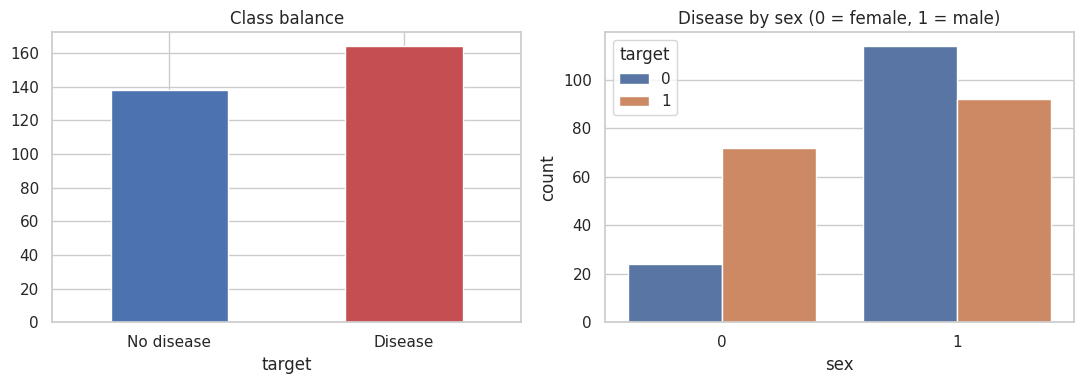

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df["target"].value_counts().sort_index().rename({0: "No disease", 1: "Disease"}).plot(kind="bar", ax=ax[0], color=["#4c72b0", "#c44e52"], rot=0)
ax[0].set_title("Class balance")
sns.countplot(data=df, x="sex", hue="target", ax=ax[1])
ax[1].set_title("Disease by sex (0 = female, 1 = male)")
plt.tight_layout(); plt.savefig("images/class_balance_sex.png", dpi=130); plt.show()

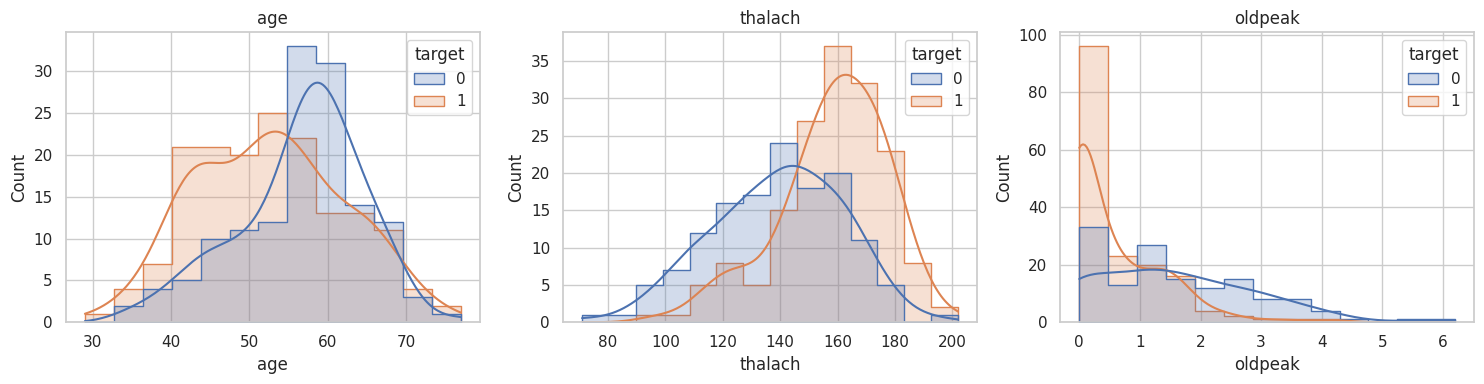

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col in zip(ax, ["age", "thalach", "oldpeak"]):
    sns.histplot(data=df, x=col, hue="target", kde=True, ax=a, element="step")
    a.set_title(col)
plt.tight_layout(); plt.savefig("images/feature_distributions.png", dpi=130); plt.show()

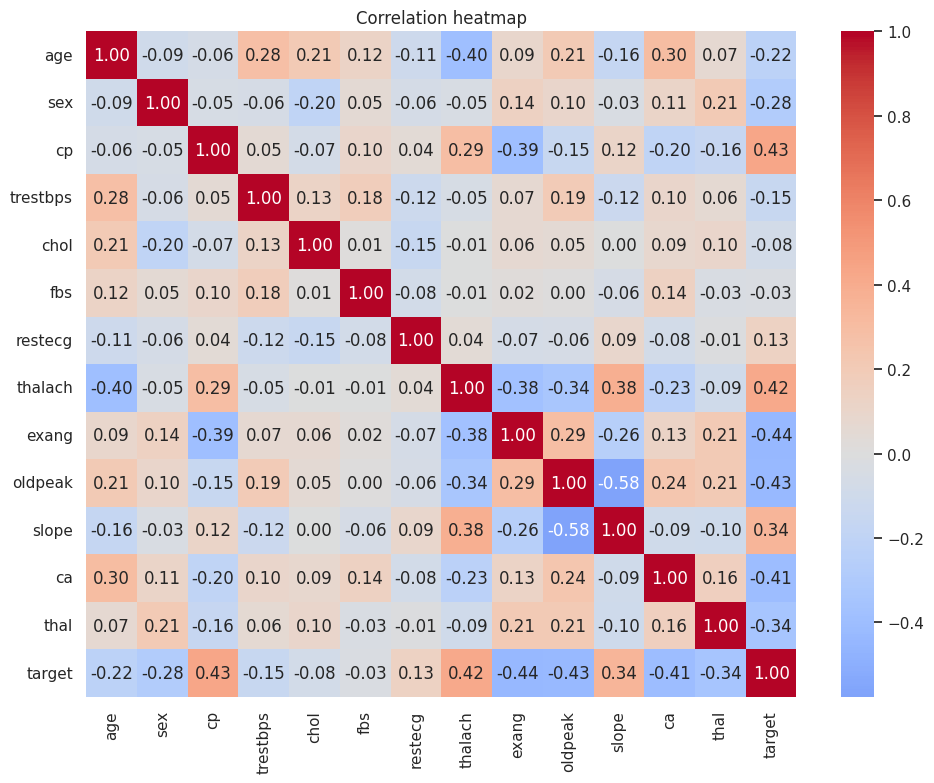

In [7]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.tight_layout(); plt.savefig("images/correlation_heatmap.png", dpi=130); plt.show()

In [8]:
df.corr()["target"].drop("target").sort_values()

exang      -0.435601
oldpeak    -0.429146
ca         -0.408992
thal       -0.343101
sex        -0.283609
age        -0.221476
trestbps   -0.146269
chol       -0.081437
fbs        -0.026826
restecg     0.134874
slope       0.343940
thalach     0.419955
cp          0.432080
Name: target, dtype: float64

## 4. Train / test split and models
Stratified 80/20 split. Logistic Regression uses scaled features; tree models do not need scaling.

In [9]:
X = df.drop("target", axis=1)
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape)

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=6, random_state=RANDOM_STATE),
}

(241, 13) (61, 13)


## 5. Evaluation
Test-set metrics plus 5-fold cross-validated accuracy (more reliable on a small dataset).

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
preds = {}
for name, m in models.items():
    m.fit(X_train, y_train)
    p = m.predict(X_test)
    preds[name] = p
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, p),
        "Precision": precision_score(y_test, p),
        "Recall": recall_score(y_test, p),
        "F1": f1_score(y_test, p),
        "CV Accuracy (5-fold)": cross_val_score(m, X, y, cv=cv, scoring="accuracy").mean(),
    })
results = pd.DataFrame(rows).set_index("Model").round(3)
results.to_csv("results.csv")
results

,Accuracy,Precision,Recall,F1,CV Accuracy (5-fold)
Model,,,,,
Logistic Regression,0.787,0.763,0.879,0.817,0.838
Decision Tree,0.803,0.744,0.970,0.842,0.761
Random Forest,0.803,0.756,0.939,0.838,0.831


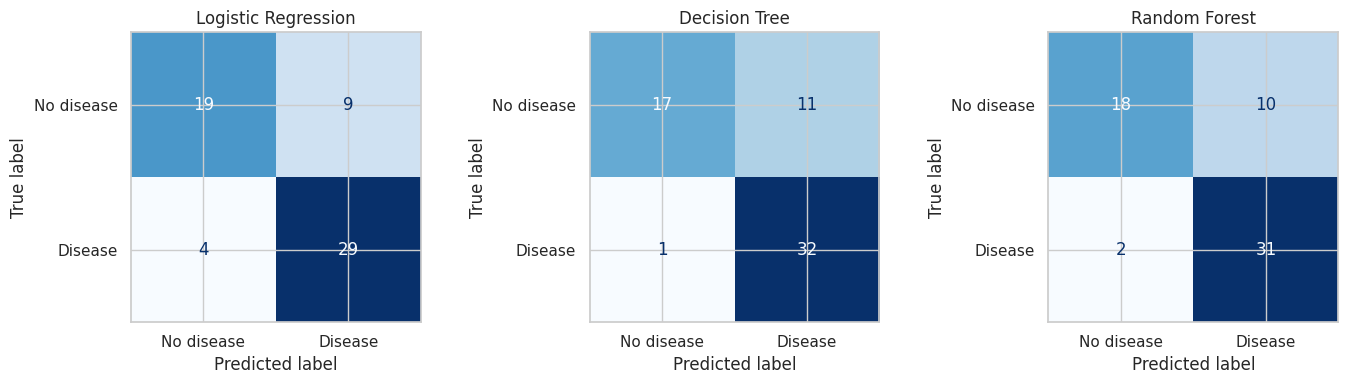

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, (name, p) in zip(ax, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, p), display_labels=["No disease", "Disease"]).plot(ax=a, colorbar=False, cmap="Blues")
    a.set_title(name)
plt.tight_layout(); plt.savefig("images/confusion_matrices.png", dpi=130); plt.show()

## 6. Feature importance (Random Forest)

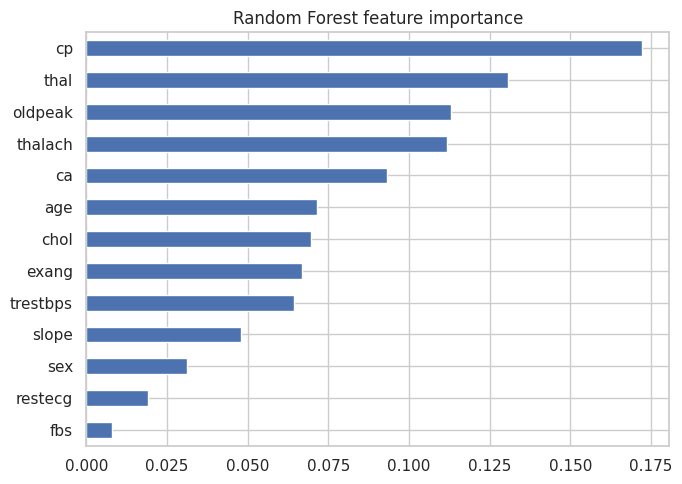

In [12]:
imp = pd.Series(models["Random Forest"].feature_importances_, index=X.columns).sort_values()
imp.plot(kind="barh", figsize=(7, 5), color="#4c72b0")
plt.title("Random Forest feature importance")
plt.tight_layout(); plt.savefig("images/feature_importance.png", dpi=130); plt.show()

## 7. Conclusion
See the results table above for the best-performing model. For a medical screening problem, **recall** matters most because missing a patient with disease is costlier than a false alarm.

**Limitations:** only ~300 patients, a single hospital dataset, and no external validation. This is a learning project, not a diagnostic tool.